# Operaciones básicas de procesamiento digital de imágenes

Sobre la imagen **Lena** (`data/lena_color.tiff`, de Gonzalez, R. C., & Woods, R. E.
(2008). *Digital image processing* (3rd ed.). Pearson Prentice Hall) se aplican cinco
operaciones clásicas:

1. **Rotación** en una posición arbitraria.
2. **Negativo** de la imagen.
3. **Umbralización** (binaria).
4. **Ecualización** de histograma.
5. **Eliminación de ruido**.

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline


def mostrar_imagenes(titulos, imagenes, cmap=None):
    fig, axes = plt.subplots(1, len(imagenes), figsize=(15, 5))
    if isinstance(axes, plt.Axes):
        axes = [axes]
    for ax, titulo, img in zip(axes, titulos, imagenes):
        ax.imshow(img, cmap=cmap)
        ax.set_title(titulo)
        ax.axis('off')
    plt.tight_layout()
    plt.show()


def mostrar_histograma(img_gray, titulo, color_curva='red'):
    plt.figure(figsize=(6, 4))
    plt.hist(img_gray.ravel(), bins=256, range=(0, 255), color=color_curva)
    plt.title(titulo)
    plt.xlabel('Nivel de gris')
    plt.ylabel('Frecuencia')
    plt.tight_layout()
    plt.show()

### Cargar imagen (Lena)

Se lee en BGR (convención de OpenCV) y se convierte a RGB para visualizarla con
matplotlib.

Ruta: data/lena_color.tiff
Dimensiones: (512, 512, 3) | dtype: uint8


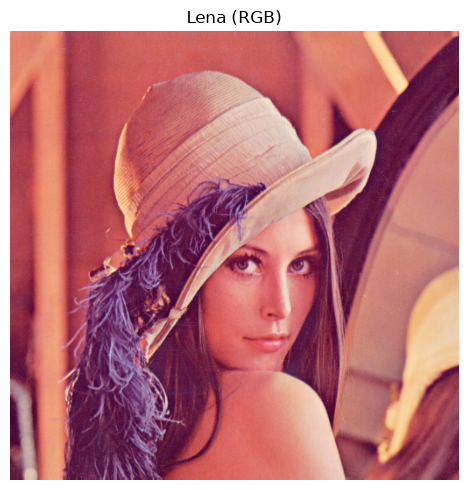

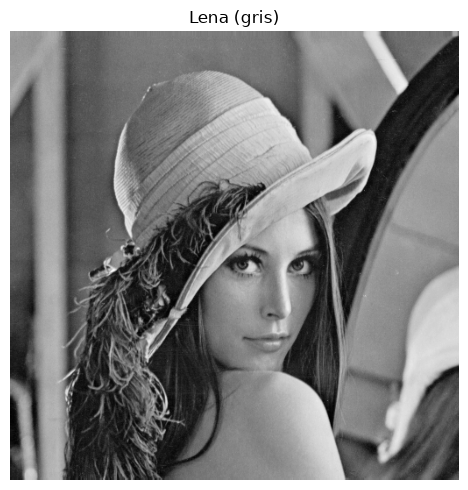

In [2]:
RUTA_IMAGEN = 'data/lena_color.tiff'
if not os.path.exists(RUTA_IMAGEN):
    RUTA_IMAGEN = 'data/Lena.tiff'

img_bgr = cv2.imread(RUTA_IMAGEN)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

print('Ruta:', RUTA_IMAGEN)
print('Dimensiones:', img_rgb.shape, '| dtype:', img_rgb.dtype)
mostrar_imagenes(['Lena (RGB)'], [img_rgb])
mostrar_imagenes(['Lena (gris)'], [img_gray], cmap='gray')

## 1. Imagen rotada

`cv2.getRotationMatrix2D` construye la matriz de rotación 2x3 alrededor de un centro
(pivote). Como la matriz no es entera, `warpAffine` debe interpolar los píxeles ausentes
(`INTER_LINEAR`); para no perder información se **amplía el lienzo** (`expandir=True`)
o se recorta el resultado al tamaño original.

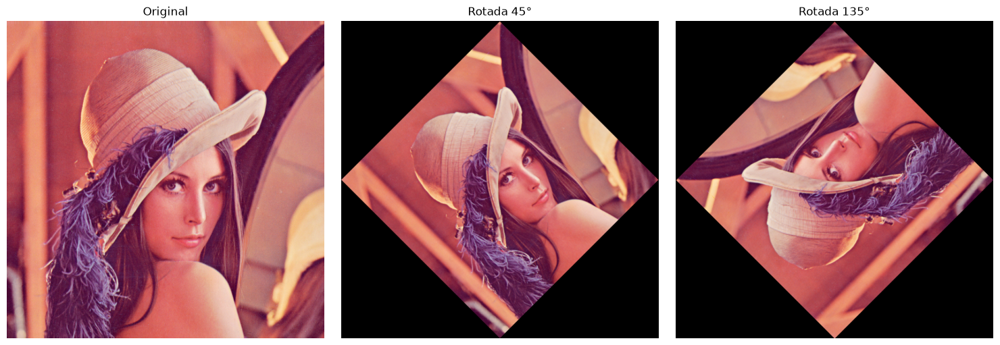

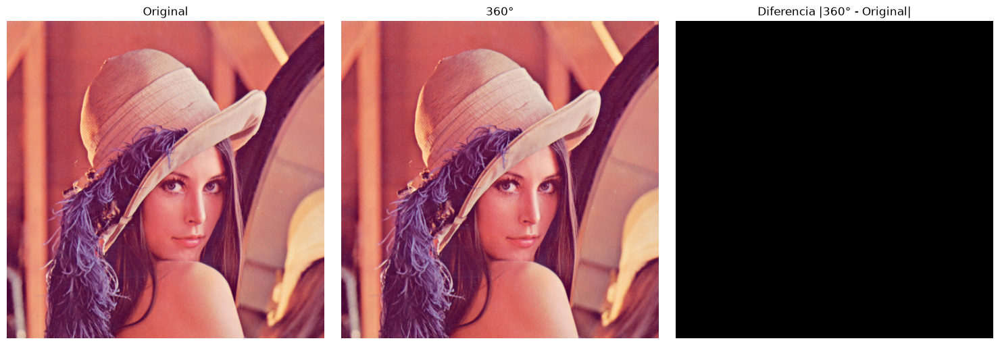

La rotación de 360° recupera la imagen original (diferencia nula).


In [3]:
def rotar_imagen(imagen, angulo, centro=None, expandir=False, borde=cv2.BORDER_CONSTANT):
    """Rota la imagen `angulo` grados en sentido antihorario alrededor de `centro`."""
    if centro is None:
        centro = (imagen.shape[1] / 2, imagen.shape[0] / 2)
    M = cv2.getRotationMatrix2D(centro, angulo, 1.0)
    tam_salida = None
    if expandir:
        cos, sen = abs(M[0, 0]), abs(M[0, 1])
        alto, ancho = imagen.shape[:2]
        nuevo_ancho = int(np.ceil(alto * sen + ancho * cos))
        nuevo_alto = int(np.ceil(alto * cos + ancho * sen))
        M[0, 2] += (nuevo_ancho / 2) - centro[0]
        M[1, 2] += (nuevo_alto / 2) - centro[1]
        tam_salida = (nuevo_ancho, nuevo_alto)
    return cv2.warpAffine(imagen, M, tam_salida or (imagen.shape[1], imagen.shape[0]),
                          flags=cv2.INTER_LINEAR, borderMode=borde)


img_rot45 = rotar_imagen(img_rgb, 45, expandir=True)
img_rot135 = rotar_imagen(img_rgb, 135, expandir=True)
mostrar_imagenes(['Original', 'Rotada 45°', 'Rotada 135°'], [img_rgb, img_rot45, img_rot135])

# Giro completo de 360° para comprobar que la transformación es reversible
img_rot360 = rotar_imagen(img_rgb, 360)
mostrar_imagenes(['Original', '360°', 'Diferencia |360° - Original|'],
                 [img_rgb, img_rot360, cv2.absdiff(img_rgb, img_rot360)])
print('La rotación de 360° recupera la imagen original (diferencia nula).')

## 2. Negativo de la imagen

Invierte los niveles: `negativo = 255 - imagen`. Es una operación punto a punto sobre
cada canal (inversión radiométrica), útil para revelar detalle en zonas oscuras o para
invertir documentos escaneados.

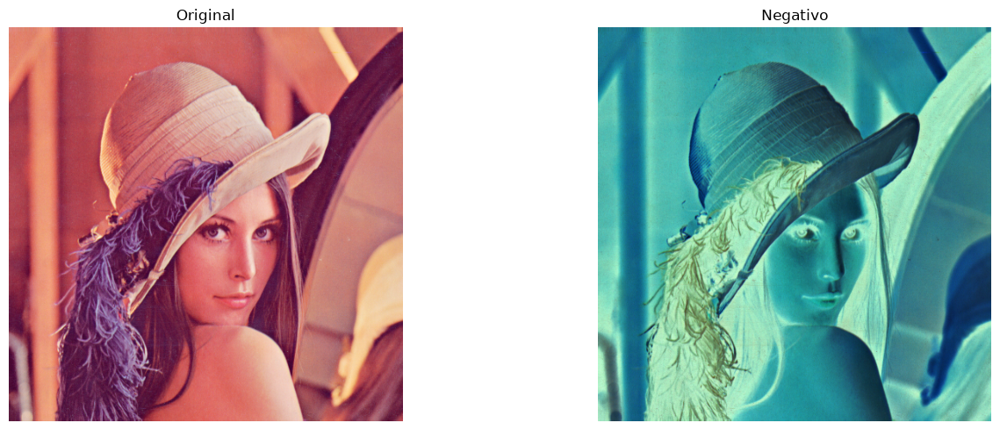

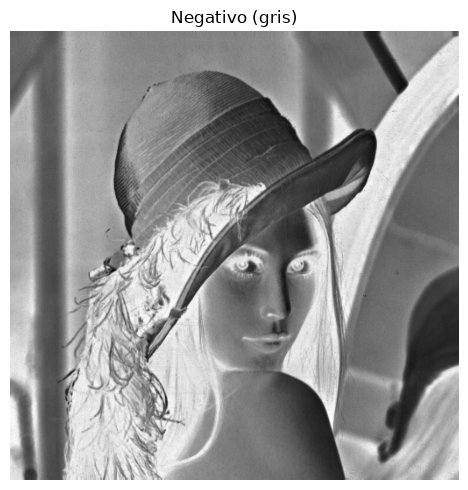

¿Doble negativo == original? True


In [4]:
img_neg = 255 - img_rgb
mostrar_imagenes(['Original', 'Negativo'], [img_rgb, img_neg])
mostrar_imagenes(['Negativo (gris)'], [cv2.cvtColor(img_neg, cv2.COLOR_RGB2GRAY)], cmap='gray')

# El negativo es involutivo: aplicarlo dos veces devuelve la original
print('¿Doble negativo == original?', np.array_equal(255 - img_neg, img_rgb))

## 3. Imagen umbralizada

Umbral fijo (`cv2.threshold`) frente a **Otsu**, que calcula el umbral que maximiza la
varianza entre clases (umbral automático, sin parámetro). Además se muestra el resultado
con el canal alfa para ver exactamente qué píxeles quedan fuera.

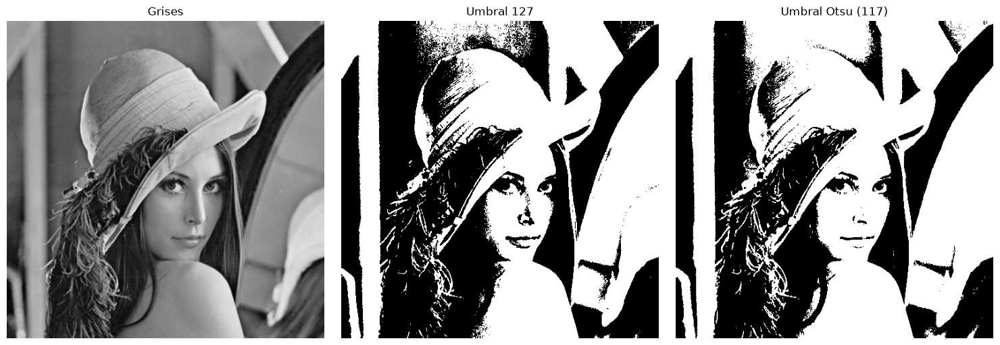

Umbral de Otsu calculado automáticamente: 117.0
Proporción de píxeles blancos: 58.36%


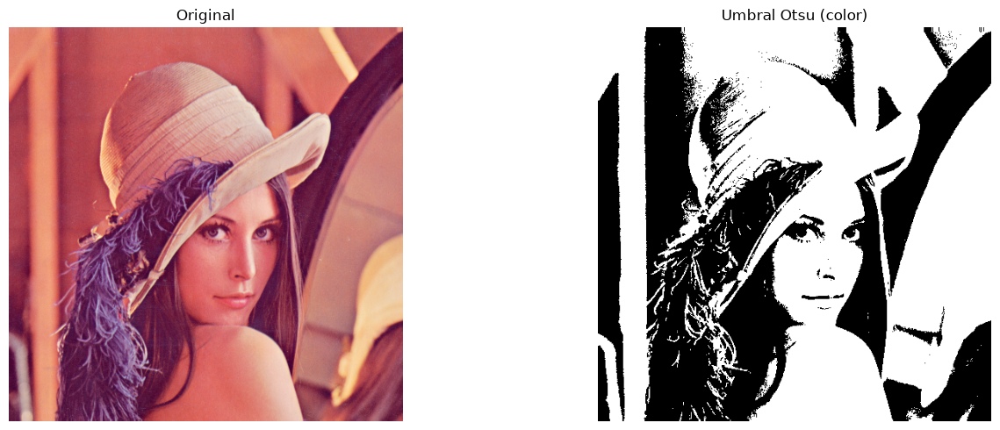

In [5]:
_, img_bin_127 = cv2.threshold(img_gray, 127, 255, cv2.THRESH_BINARY)
umbral_otsu, img_bin_otsu = cv2.threshold(img_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

mostrar_imagenes(['Grises', 'Umbral 127', 'Umbral Otsu (%d)' % umbral_otsu],
                 [img_gray, img_bin_127, img_bin_otsu], cmap='gray')
print('Umbral de Otsu calculado automáticamente:', umbral_otsu)
print('Proporción de píxeles blancos: %.2f%%' % (100 * np.mean(img_bin_otsu > 0)))

# Umbral adaptativo (gaussiano) para iluminación no uniforme
img_otsu_rgb = cv2.cvtColor(img_bin_otsu, cv2.COLOR_GRAY2RGB)
img_umbralado = np.where(img_otsu_rgb == 255, 255, np.where(img_otsu_rgb == 0, 0, img_otsu_rgb)).astype(np.uint8)
mostrar_imagenes(['Original', 'Umbral Otsu (color)'], [img_rgb, img_umbralado])

## 4. Imagen ecualizada

La ecualización de histograma reparte los píxeles de forma uniforme en el rango,
aumentando el contraste global. Se compara:
- Ecualización global (histograma sobre toda la imagen).
- **CLAHE**, ecualización *adaptativa con ecualización de histograma limitada*
  (`cv2.createCLAHE`), que mejora el contraste local por teselas y evita la
  sobreamplificación del ruido.

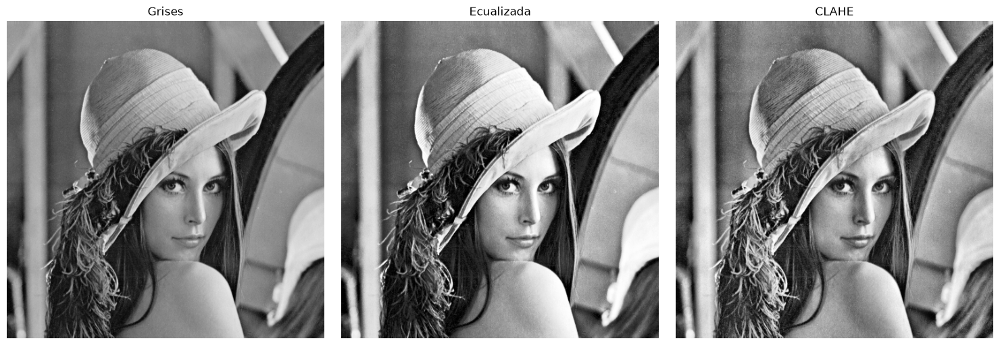

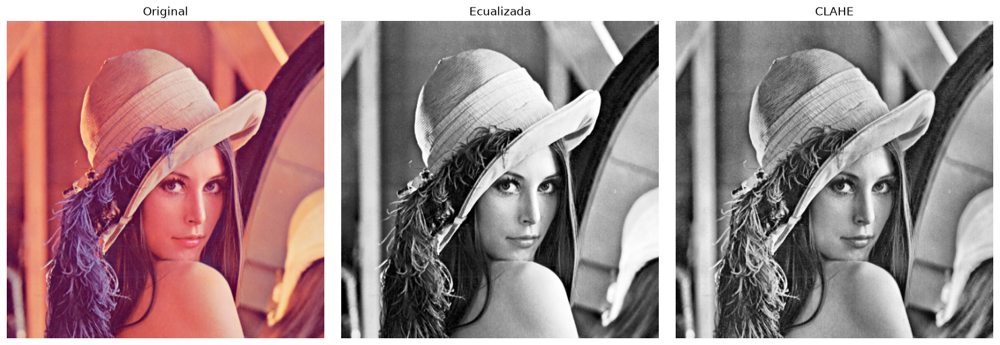

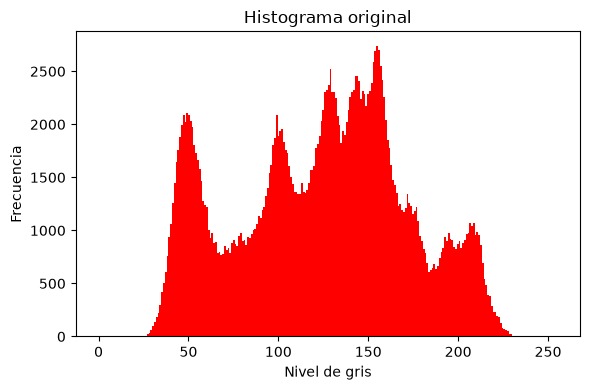

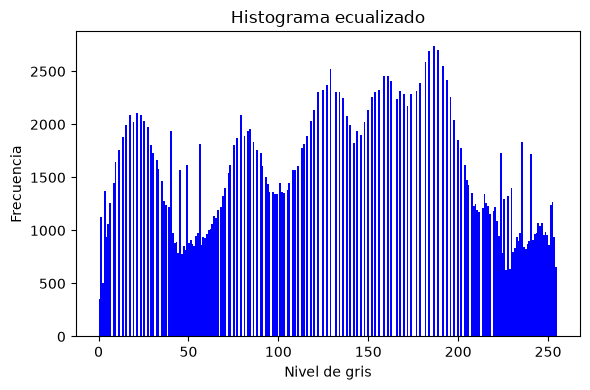

Desviación típica de intensidades: 47.86 -> 73.59


In [6]:
img_ec = cv2.equalizeHist(img_gray)

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
img_clahe = clahe.apply(img_gray)

mostrar_imagenes(['Grises', 'Ecualizada', 'CLAHE'],
                 [img_gray, img_ec, img_clahe], cmap='gray')
mostrar_imagenes(['Original', 'Ecualizada', 'CLAHE'],
                 [img_rgb, cv2.cvtColor(img_ec, cv2.COLOR_GRAY2RGB),
                  cv2.cvtColor(img_clahe, cv2.COLOR_GRAY2RGB)])

mostrar_histograma(img_gray, 'Histograma original')
mostrar_histograma(img_ec, 'Histograma ecualizado', 'blue')

desviacion_antes = img_gray.std()
desviacion_despues = img_ec.std()
print('Desviación típica de intensidades: %.2f -> %.2f' % (desviacion_antes, desviacion_despues))

## 5. Eliminación del ruido

Se contamina la imagen con dos ruidos típicos —**sal y pimienta** (ruido impulsivo)
y **gaussiano** (ruido térmico/sensor)— y se eliminan con tres filtros:

| Filtro | Ruido que elimina | Nota |
|---|---|---|
| `cv2.medianBlur` | sal y pimienta | No crea píxeles nuevos, preserva bordes |
| `cv2.bilateralFilter` | gaussiano | Suaviza sin difuminar los bordes |
| `cv2.fastNlMeansDenoisingColored` | gaussiano | Non-local means, mejor en color |

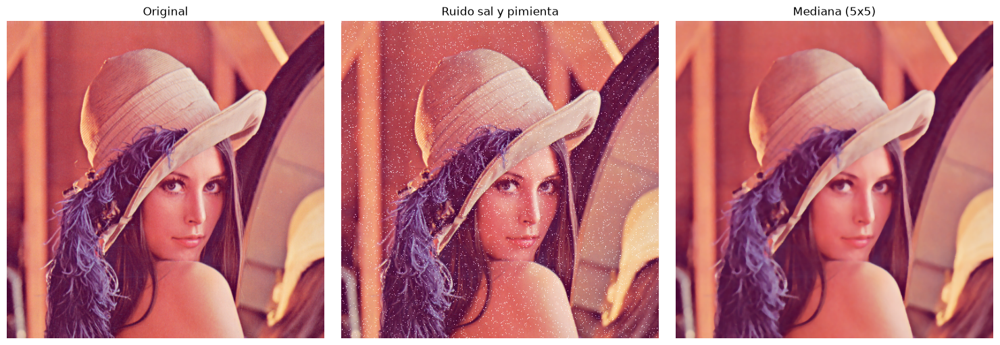

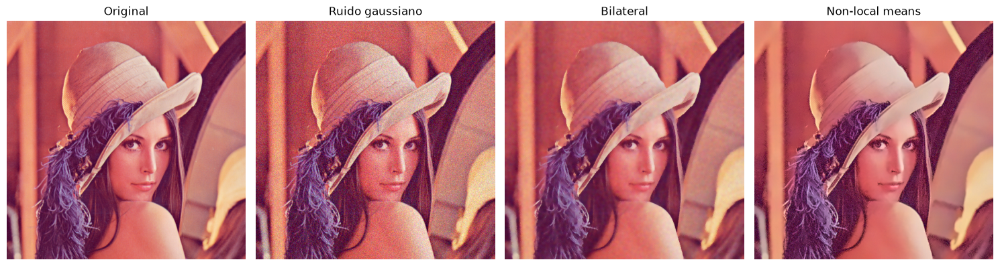

RMSE ruido sal y pimienta vs original: 20.69
RMSE mediana (5x5)     vs original: 7.54
RMSE ruido gaussiano   vs original: 19.70
RMSE bilateral         vs original: 7.53
RMSE non-local means   vs original: 10.44


In [7]:
# --- Ruido sintético ---
rng = np.random.default_rng(42)

ruido_sp = rng.integers(0, 2, size=img_rgb.shape[:2], dtype=np.uint8) * 255
ruido_sp = np.where(rng.random(img_rgb.shape[:2]) < 0.05, ruido_sp, 0).astype(np.uint8)
img_sp = cv2.addWeighted(img_rgb, 1.0, np.dstack([ruido_sp] * 3), 0.7, 0)

ruido_gauss = rng.normal(0, 20, img_rgb.shape)
img_gauss = np.clip(img_rgb.astype(np.float32) + ruido_gauss, 0, 255).astype(np.uint8)

# --- Eliminación de ruido ---
img_mediana = cv2.medianBlur(img_sp, 5)
img_bilateral = cv2.bilateralFilter(img_gauss, 9, 75, 75)
img_nlm = cv2.fastNlMeansDenoisingColored(img_gauss, None, 10, 10, 7, 21)

mostrar_imagenes(['Original', 'Ruido sal y pimienta', 'Mediana (5x5)'],
                 [img_rgb, img_sp, img_mediana])
mostrar_imagenes(['Original', 'Ruido gaussiano', 'Bilateral', 'Non-local means'],
                 [img_rgb, img_gauss, img_bilateral, img_nlm])


def rmse(a, b):
    a, b = a.astype(np.float32), b.astype(np.float32)
    return float(np.sqrt(np.mean((a - b) ** 2)))


print('RMSE ruido sal y pimienta vs original: %.2f' % rmse(img_sp, img_rgb))
print('RMSE mediana (5x5)     vs original: %.2f' % rmse(img_mediana, img_rgb))
print('RMSE ruido gaussiano   vs original: %.2f' % rmse(img_gauss, img_rgb))
print('RMSE bilateral         vs original: %.2f' % rmse(img_bilateral, img_rgb))
print('RMSE non-local means   vs original: %.2f' % rmse(img_nlm, img_rgb))

## Pipeline completo sobre Lena

Todas las operaciones aplicadas en orden: carga → ecualización → eliminación de ruido →
umbralización (Otsu) → negativo → rotación.

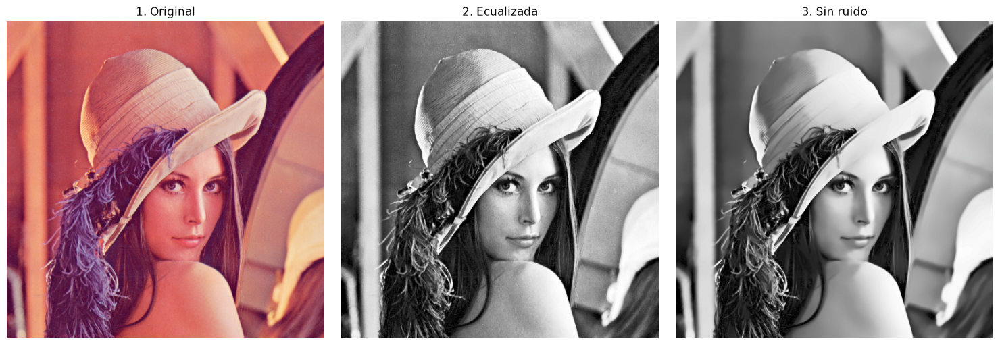

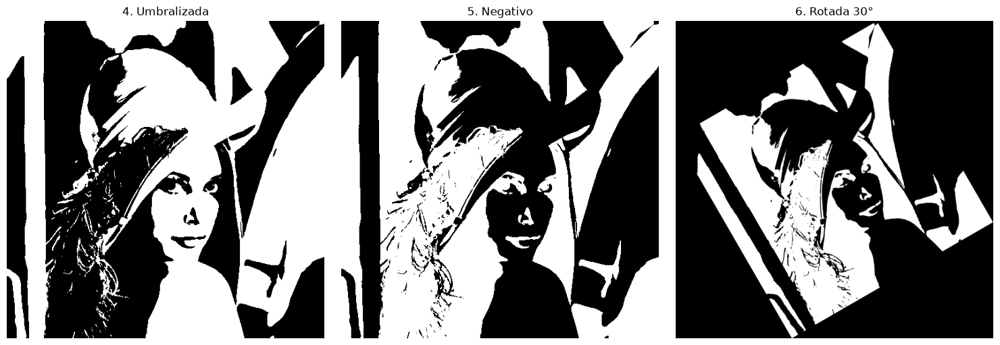

In [8]:
img_paso1 = cv2.equalizeHist(cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY))
img_paso1 = cv2.cvtColor(img_paso1, cv2.COLOR_GRAY2RGB)
img_paso2 = cv2.fastNlMeansDenoisingColored(img_paso1, None, 10, 10, 7, 21)
_, img_paso3 = cv2.threshold(cv2.cvtColor(img_paso2, cv2.COLOR_RGB2GRAY), 0, 255,
                              cv2.THRESH_BINARY + cv2.THRESH_OTSU)
img_paso3 = cv2.cvtColor(img_paso3, cv2.COLOR_GRAY2RGB)
img_paso4 = 255 - img_paso3
img_paso5 = rotar_imagen(img_paso4, 30, expandir=True)

mostrar_imagenes(['1. Original', '2. Ecualizada', '3. Sin ruido'],
                 [img_rgb, img_paso1, img_paso2])
mostrar_imagenes(['4. Umbralizada', '5. Negativo', '6. Rotada 30°'],
                 [img_paso3, img_paso4, img_paso5])

## Conclusiones

- **Rotación**: `getRotationMatrix2D` + `warpAffine`; `expandir=True` evita recortar las
  esquinas y el modo de borde controla el relleno exterior.
- **Negativo**: inversión radiométrica por canal (`255 - I`), involutiva y trivialmente
  rápida.
- **Umbralización**: el valor fijo depende del histograma; **Otsu** lo obtiene de forma
  automática y es el punto de partida habitual, mientras que el umbral adaptativo es
  mejor con iluminación no uniforme.
- **Ecualización**: mejora el contraste global pero amplifica el ruido; **CLAHE** lo
  limita por teselas y da un resultado más natural.
- **Ruido**: la **mediana** es la opción para ruido impulsivo (sal y pimienta) y
  **bilateral / non-local means** para ruido gaussiano, preservando los bordes.